<a href="https://colab.research.google.com/github/tffnnnnnn/Machine_Learning_MASnI3/blob/main/SCIGEN_01_MASnI%E2%82%83.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **1.1**

In [ ]:
# takes long (~5-10 min first run) — clones repo, installs deps, downloads model
# --- Run once per Colab session (skip if you already ran 00_setup.ipynb) ---
import os, shutil, subprocess, sys

REPO_URL = 'https://github.com/RyotaroOKabe/APS_demo_SCIGEN.git'
PROJECT_DIR = '/content/APS_demo_SCIGEN'

# Clone repo if needed
if not os.path.exists(os.path.join(PROJECT_DIR, '.git')):
    if os.path.exists(PROJECT_DIR):
        shutil.rmtree(PROJECT_DIR)
    os.system(f'git clone {REPO_URL} {PROJECT_DIR}')

# Install all tutorial dependencies from the shared requirements file
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                       '-r', f'{PROJECT_DIR}/requirements-colab.txt'])
os.environ.setdefault('PROJECT_ROOT', PROJECT_DIR)
print('Ready.')

Ready.


In [ ]:
from pymatgen.core import Structure, Lattice
import numpy as np

# **1.2**

In [ ]:
from pymatgen.core import Lattice, Structure

# Define the lattice: tetragonal MASnI3
lattice = Lattice.tetragonal(a=6.2302, c=6.2316)

# Define species and fractional coordinates
species = [
    'Sn', 'I', 'I', 'I',
    'C', 'N',
    'H', 'H', 'H', 'H', 'H', 'H'
]

frac_coords = [
    [0.50000, 0.50000, 0.50000],  # Sn
    [0.50000, 0.50000, 0.00000],  # I
    [0.50000, 0.00000, 0.50000],  # I
    [0.00000, 0.50000, 0.50000],  # I

    [0.00000, 0.00000, 0.88205],  # C
    [0.00000, 0.00000, 0.11795],  # N

    [0.15738, 0.00000, 0.82642],  # H
    [0.92131, 0.13630, 0.82642],  # H
    [0.92131, 0.86370, 0.82642],  # H
    [0.07869, 0.13630, 0.17358],  # H
    [0.84262, 0.00000, 0.17358],  # H
    [0.07869, 0.86370, 0.17358],  # H
]

masni3 = Structure(lattice, species, frac_coords)

print(masni3)

# Export CIF file
masni3.to(fmt="cif", filename="MASnI3_initial.cif")

Full Formula (Sn1 H6 C1 I3 N1)
Reduced Formula: SnH6CI3N
abc   :   6.230200   6.230200   6.231600
angles:  90.000000  90.000000  90.000000
pbc   :       True       True       True
Sites (12)
  #  SP          a       b        c
---  ----  -------  ------  -------
  0  Sn    0.5      0.5     0.5
  1  I     0.5      0.5     0
  2  I     0.5      0       0.5
  3  I     0        0.5     0.5
  4  C     0        0       0.88205
  5  N     0        0       0.11795
  6  H     0.15738  0       0.82642
  7  H     0.92131  0.1363  0.82642
  8  H     0.92131  0.8637  0.82642
  9  H     0.07869  0.1363  0.17358
 10  H     0.84262  0       0.17358
 11  H     0.07869  0.8637  0.17358


"# generated using pymatgen\ndata_SnH6CI3N\n_symmetry_space_group_name_H-M   'P 1'\n_cell_length_a   6.23020000\n_cell_length_b   6.23020000\n_cell_length_c   6.23160000\n_cell_angle_alpha   90.00000000\n_cell_angle_beta   90.00000000\n_cell_angle_gamma   90.00000000\n_symmetry_Int_Tables_number   1\n_chemical_formula_structural   SnH6CI3N\n_chemical_formula_sum   'Sn1 H6 C1 I3 N1'\n_cell_volume   241.88199704\n_cell_formula_units_Z   1\nloop_\n _symmetry_equiv_pos_site_id\n _symmetry_equiv_pos_as_xyz\n  1  'x, y, z'\nloop_\n _atom_site_type_symbol\n _atom_site_label\n _atom_site_symmetry_multiplicity\n _atom_site_fract_x\n _atom_site_fract_y\n _atom_site_fract_z\n _atom_site_occupancy\n  Sn  Sn0  1  0.50000000  0.50000000  0.50000000  1\n  I  I1  1  0.50000000  0.50000000  0.00000000  1\n  I  I2  1  0.50000000  0.00000000  0.50000000  1\n  I  I3  1  0.00000000  0.50000000  0.50000000  1\n  C  C4  1  0.00000000  0.00000000  0.88205000  1\n  N  N5  1  0.00000000  0.00000000  0.11795000 

# **1.2.1**

In [ ]:
print(f'Formula:           {masni3.composition.reduced_formula}')
print(f'Number of atoms:   {masni3.num_sites}')
print(f'Volume:            {masni3.volume:.2f} Å³')
print(f'Density:           {masni3.density:.3f} g/cm³')
print()
print('Lattice parameters:')
print(f'  a={masni3.lattice.a:.2f} Å, b={masni3.lattice.b:.2f} Å, c={masni3.lattice.c:.2f} Å')
print(f'  α={masni3.lattice.alpha:.1f}°, β={masni3.lattice.beta:.1f}°, γ={masni3.lattice.gamma:.1f}°')
print()
print('Fractional coordinates:')
for site in masni3:
    print(f'  {site.species_string:>4s}  {site.frac_coords}')

Formula:           SnH6CI3N
Number of atoms:   12
Volume:            241.88 Å³
Density:           3.649 g/cm³

Lattice parameters:
  a=6.23 Å, b=6.23 Å, c=6.23 Å
  α=90.0°, β=90.0°, γ=90.0°

Fractional coordinates:
    Sn  [0.5 0.5 0.5]
     I  [0.5 0.5 0. ]
     I  [0.5 0.  0.5]
     I  [0.  0.5 0.5]
     C  [0.      0.      0.88205]
     N  [0.      0.      0.11795]
     H  [0.15738 0.      0.82642]
     H  [0.92131 0.1363  0.82642]
     H  [0.92131 0.8637  0.82642]
     H  [0.07869 0.1363  0.17358]
     H  [0.84262 0.      0.17358]
     H  [0.07869 0.8637  0.17358]


# **1.3**

In [ ]:
# The (L, X, A) representation of MASnI3

print("=" * 55)
print("LATTICE (L) — the periodic box")
print("=" * 55)
print(f"  Lengths: a={masni3.lattice.a:.2f} Å, b={masni3.lattice.b:.2f} Å, c={masni3.lattice.c:.2f} Å")
print(f"  Angles:  α={masni3.lattice.alpha:.1f}°, β={masni3.lattice.beta:.1f}°, γ={masni3.lattice.gamma:.1f}°")
print(f"  Lattice matrix (rows = vectors a, b, c):")
for row in masni3.lattice.matrix:
    print(f"    [{row[0]:8.4f}  {row[1]:8.4f}  {row[2]:8.4f}]")

print()
print("=" * 55)
print("FRACTIONAL COORDINATES (X) — atom positions in [0, 1)")
print("=" * 55)
for i, site in enumerate(masni3):
    f = site.frac_coords
    print(f"  Atom {i}: [{f[0]:.4f}, {f[1]:.4f}, {f[2]:.4f}]")

print()
print("=" * 55)
print("ATOM TYPES (A) — chemical species at each position")
print("=" * 55)
species = [site.species_string for site in masni3]
print(f"  {species}")
print(f"  ({len(set(species))} unique species: {sorted(set(species))})")

LATTICE (L) — the periodic box
  Lengths: a=6.23 Å, b=6.23 Å, c=6.23 Å
  Angles:  α=90.0°, β=90.0°, γ=90.0°
  Lattice matrix (rows = vectors a, b, c):
    [  6.2302    0.0000    0.0000]
    [  0.0000    6.2302    0.0000]
    [  0.0000    0.0000    6.2316]

FRACTIONAL COORDINATES (X) — atom positions in [0, 1)
  Atom 0: [0.5000, 0.5000, 0.5000]
  Atom 1: [0.5000, 0.5000, 0.0000]
  Atom 2: [0.5000, 0.0000, 0.5000]
  Atom 3: [0.0000, 0.5000, 0.5000]
  Atom 4: [0.0000, 0.0000, 0.8821]
  Atom 5: [0.0000, 0.0000, 0.1179]
  Atom 6: [0.1574, 0.0000, 0.8264]
  Atom 7: [0.9213, 0.1363, 0.8264]
  Atom 8: [0.9213, 0.8637, 0.8264]
  Atom 9: [0.0787, 0.1363, 0.1736]
  Atom 10: [0.8426, 0.0000, 0.1736]
  Atom 11: [0.0787, 0.8637, 0.1736]

ATOM TYPES (A) — chemical species at each position
  ['Sn', 'I', 'I', 'I', 'C', 'N', 'H', 'H', 'H', 'H', 'H', 'H']
  (5 unique species: ['C', 'H', 'I', 'N', 'Sn'])


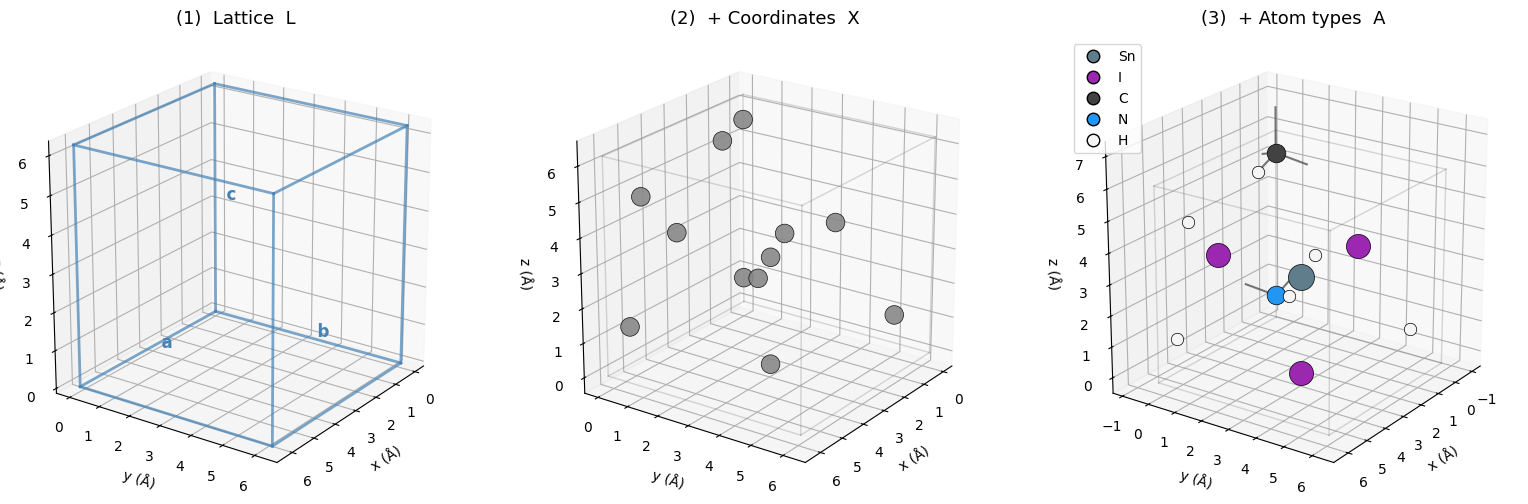

MASnI3 is defined by: L (lattice), X (fractional coordinates), A (atomic species)


In [ ]:
# Visual decomposition of MASnI3: Lattice | + Coordinates | + Atom types

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np

L = masni3.lattice.matrix  # rows = a, b, c vectors

def draw_box(ax, L, color='black', lw=1.0, alpha=0.3):
    """Draw the parallelepiped unit cell."""
    o = np.zeros(3)
    a, b, c = L[0], L[1], L[2]

    edges = [
        (o, a), (o, b), (o, c),
        (a, a+b), (a, a+c),
        (b, a+b), (b, b+c),
        (c, a+c), (c, b+c),
        (a+b, a+b+c),
        (a+c, a+b+c),
        (b+c, a+b+c)
    ]

    for p1, p2 in edges:
        ax.plot3D(*zip(p1, p2), color=color, lw=lw, alpha=alpha)


# Element colors and sizes
colors_map = {
    'Sn': '#607D8B',  # Blue gray
    'I':  '#9C27B0',  # Purple
    'C':  '#424242',  # Dark gray
    'N':  '#2196F3',  # Blue
    'H':  '#F5F5F5'   # White
}

sizes_map = {
    'Sn': 350,
    'I': 300,
    'C': 180,
    'N': 180,
    'H': 80
}

fig = plt.figure(figsize=(16, 5))


# --- Panel 1: Lattice only ---
ax1 = fig.add_subplot(131, projection='3d')

draw_box(ax1, L, color='steelblue', lw=2.0, alpha=0.7)

for vec, label in zip(L, ['a', 'b', 'c']):
    ax1.text(
        vec[0]*0.5,
        vec[1]*0.5,
        vec[2]*0.5,
        f'  {label}',
        fontsize=12,
        fontweight='bold',
        color='steelblue'
    )

ax1.set_title('(1)  Lattice  L', fontsize=13, pad=10)


# --- Panel 2: Lattice + atom positions (all gray) ---
ax2 = fig.add_subplot(132, projection='3d')

draw_box(ax2, L, color='gray', lw=1.0, alpha=0.3)

cart = masni3.cart_coords

ax2.scatter(
    cart[:, 0],
    cart[:, 1],
    cart[:, 2],
    s=180,
    c='#888888',
    edgecolors='black',
    linewidths=0.5,
    alpha=0.9,
    depthshade=True
)

ax2.set_title('(2)  + Coordinates  X', fontsize=13, pad=10)


# --- Panel 3: Lattice + positions + element colors ---
ax3 = fig.add_subplot(133, projection='3d')

draw_box(ax3, L, color='gray', lw=1.0, alpha=0.3)

for site in masni3:
    c_xyz = site.coords
    element = site.species_string

    ax3.scatter(
        c_xyz[0],
        c_xyz[1],
        c_xyz[2],
        s=sizes_map.get(element, 150),
        c=colors_map.get(element, '#888888'),
        edgecolors='black',
        linewidths=0.5,
        depthshade=True
    )


# Draw bonds within the MA+ molecule
# Atom indices: C=4, N=5, H=6~11
bonds = [
    (4, 5),  # C-N
    (4, 6), (4, 7), (4, 8),  # C-H
    (5, 9), (5, 10), (5, 11)  # N-H
]

for i, j in bonds:
    p1 = masni3[i].coords
    p2 = masni3[j].coords

    # Minimum-image correction for periodic boundaries
    delta_frac = (
        masni3[j].frac_coords -
        masni3[i].frac_coords
    )
    delta_frac -= np.round(delta_frac)

    p2_corrected = p1 + delta_frac @ L

    ax3.plot(
        [p1[0], p2_corrected[0]],
        [p1[1], p2_corrected[1]],
        [p1[2], p2_corrected[2]],
        color='#555555',
        lw=1.5,
        alpha=0.8
    )


# Legend
handles = [
    Line2D(
        [0], [0],
        marker='o',
        color='w',
        markerfacecolor=color,
        markeredgecolor='black',
        markersize=9,
        label=element
    )
    for element, color in colors_map.items()
]

ax3.legend(
    handles=handles,
    loc='upper left',
    fontsize=10
)

ax3.set_title('(3)  + Atom types  A', fontsize=13, pad=10)


# --- Common plot settings ---
for ax in [ax1, ax2, ax3]:
    ax.set_xlabel('x (Å)')
    ax.set_ylabel('y (Å)')
    ax.set_zlabel('z (Å)')

    ax.set_box_aspect([1, 1, 1])

    ax.view_init(elev=22, azim=35)

plt.tight_layout()
plt.show()

print(
    "MASnI3 is defined by: "
    "L (lattice), X (fractional coordinates), "
    "A (atomic species)"
)

# **1.4**

In [ ]:
from pymatgen.symmetry.analyzer import SpacegroupAnalyzer

# MASnI3 symmetry analysis
sga = SpacegroupAnalyzer(masni3, symprec=0.01)

masni3_conv = sga.get_conventional_standard_structure()
masni3_prim = sga.get_primitive_standard_structure()

print("Conventional cell:")
print(f"  Atoms:    {masni3_conv.num_sites}")
print(f"  Volume:   {masni3_conv.volume:.1f} Å³")
print(f"  Lattice:  a={masni3_conv.lattice.a:.2f}, b={masni3_conv.lattice.b:.2f}, c={masni3_conv.lattice.c:.2f}")
print(f"  Angles:   α={masni3_conv.lattice.alpha:.1f}°, β={masni3_conv.lattice.beta:.1f}°, γ={masni3_conv.lattice.gamma:.1f}°")
print()

print("Primitive cell:")
print(f"  Atoms:    {masni3_prim.num_sites}")
print(f"  Volume:   {masni3_prim.volume:.1f} Å³")
print(f"  Lattice:  a={masni3_prim.lattice.a:.2f}, b={masni3_prim.lattice.b:.2f}, c={masni3_prim.lattice.c:.2f}")
print(f"  Angles:   α={masni3_prim.lattice.alpha:.1f}°, β={masni3_prim.lattice.beta:.1f}°, γ={masni3_prim.lattice.gamma:.1f}°")
print()

print(f"Volume ratio: {masni3_conv.volume / masni3_prim.volume:.1f}x")
print(f"Atom ratio:   {masni3_conv.num_sites / masni3_prim.num_sites:.1f}x")

print()
print("Space group:")
print(f"  Symbol: {sga.get_space_group_symbol()}")
print(f"  Number: {sga.get_space_group_number()}")

Conventional cell:
  Atoms:    12
  Volume:   241.9 Å³
  Lattice:  a=6.23, b=6.23, c=6.23
  Angles:   α=90.0°, β=90.0°, γ=90.0°

Primitive cell:
  Atoms:    12
  Volume:   241.9 Å³
  Lattice:  a=6.23, b=6.23, c=6.23
  Angles:   α=90.0°, β=90.0°, γ=90.0°

Volume ratio: 1.0x
Atom ratio:   1.0x

Space group:
  Symbol: Pm
  Number: 6


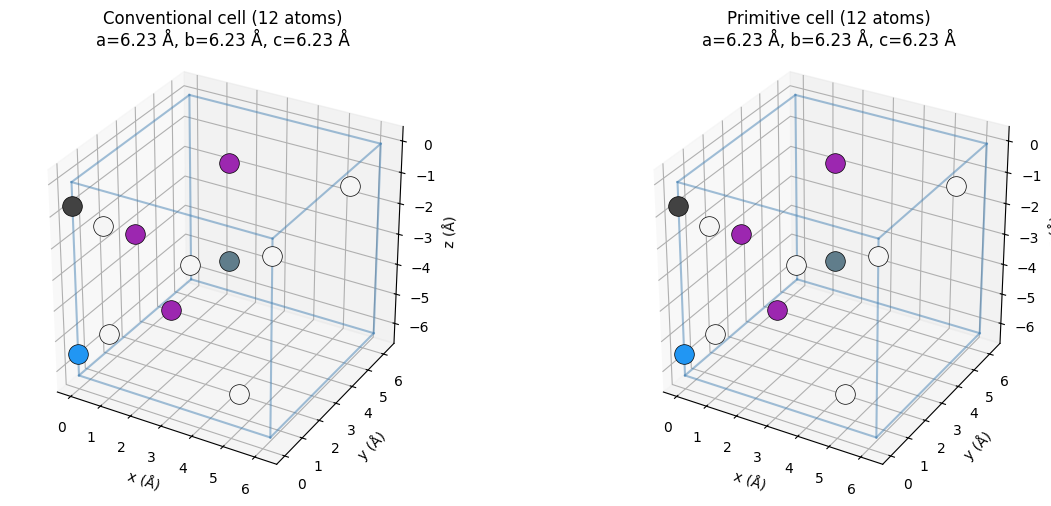

Both unit cells tile to produce the same infinite MASnI3 crystal.
The cell shapes depend on the detected crystal symmetry.


In [ ]:
# Side-by-side visualization: conventional vs primitive MASnI3
import matplotlib.pyplot as plt
import numpy as np

fig = plt.figure(figsize=(13, 5))

structures = [masni3_conv, masni3_prim]

titles = [
    f'Conventional cell ({masni3_conv.num_sites} atoms)\n'
    f'a={masni3_conv.lattice.a:.2f} Å, '
    f'b={masni3_conv.lattice.b:.2f} Å, '
    f'c={masni3_conv.lattice.c:.2f} Å',

    f'Primitive cell ({masni3_prim.num_sites} atoms)\n'
    f'a={masni3_prim.lattice.a:.2f} Å, '
    f'b={masni3_prim.lattice.b:.2f} Å, '
    f'c={masni3_prim.lattice.c:.2f} Å'
]

for panel, (struct, title) in enumerate(zip(structures, titles)):
    ax = fig.add_subplot(1, 2, panel + 1, projection='3d')
    L = struct.lattice.matrix

    # Draw unit cell box
    o = np.zeros(3)
    a_vec, b_vec, c_vec = L[0], L[1], L[2]

    edges = [
        (o, a_vec), (o, b_vec), (o, c_vec),
        (a_vec, a_vec+b_vec), (a_vec, a_vec+c_vec),
        (b_vec, a_vec+b_vec), (b_vec, b_vec+c_vec),
        (c_vec, a_vec+c_vec), (c_vec, b_vec+c_vec),
        (a_vec+b_vec, a_vec+b_vec+c_vec),
        (a_vec+c_vec, a_vec+b_vec+c_vec),
        (b_vec+c_vec, a_vec+b_vec+c_vec)
    ]

    for p1, p2 in edges:
        ax.plot3D(
            *zip(p1, p2),
            color='steelblue',
            lw=1.5,
            alpha=0.5
        )

    # Draw atoms with element colors
    colors_map = {
        'Sn': '#607D8B',
        'I':  '#9C27B0',
        'C':  '#424242',
        'N':  '#2196F3',
        'H':  '#F5F5F5'
    }

    for site in struct:
        col = colors_map.get(site.species_string, '#888888')

        ax.scatter(
            *site.coords,
            s=200,
            c=col,
            edgecolors='black',
            linewidths=0.5,
            zorder=5
        )

    ax.set_title(title, fontsize=12)
    ax.set_xlabel('x (Å)')
    ax.set_ylabel('y (Å)')
    ax.set_zlabel('z (Å)')
    ax.set_box_aspect([1, 1, 1])

plt.tight_layout()
plt.show()

print("Both unit cells tile to produce the same infinite MASnI3 crystal.")
print("The cell shapes depend on the detected crystal symmetry.")

# **1.5.1**

Unit cell (1x1x1):   12 atoms, volume =    241.9 Å³
Supercell (2x2x2):   96 atoms, volume =   1935.1 Å³

Volume scales by 8x = 2^3 copies of the unit cell


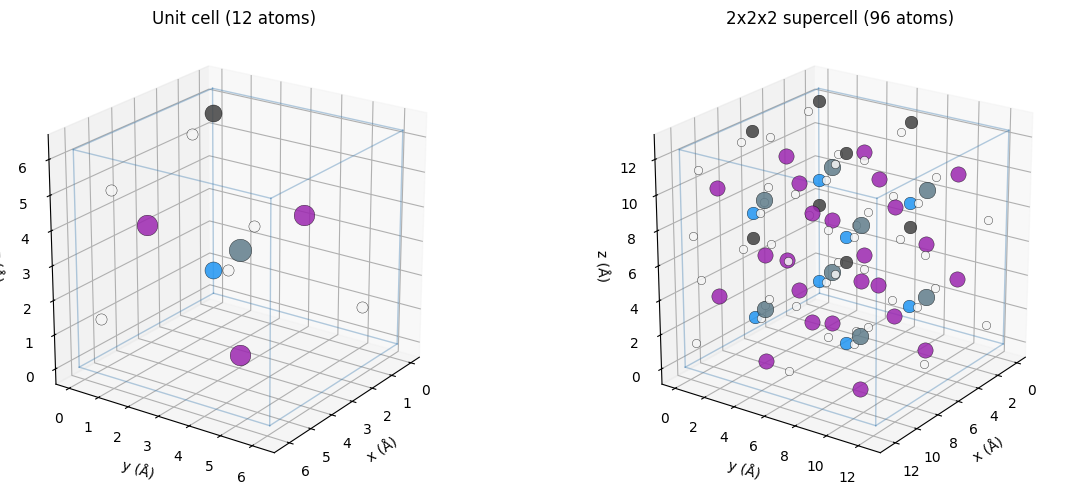

"# generated using pymatgen\ndata_SnH6CI3N\n_symmetry_space_group_name_H-M   'P 1'\n_cell_length_a   12.46040000\n_cell_length_b   12.46040000\n_cell_length_c   12.46320000\n_cell_angle_alpha   90.00000000\n_cell_angle_beta   90.00000000\n_cell_angle_gamma   90.00000000\n_symmetry_Int_Tables_number   1\n_chemical_formula_structural   SnH6CI3N\n_chemical_formula_sum   'Sn8 H48 C8 I24 N8'\n_cell_volume   1935.05597629\n_cell_formula_units_Z   8\nloop_\n _symmetry_equiv_pos_site_id\n _symmetry_equiv_pos_as_xyz\n  1  'x, y, z'\nloop_\n _atom_site_type_symbol\n _atom_site_label\n _atom_site_symmetry_multiplicity\n _atom_site_fract_x\n _atom_site_fract_y\n _atom_site_fract_z\n _atom_site_occupancy\n  Sn  Sn_1  1  0.25000000  0.25000000  0.25000000  1\n  Sn  Sn_2  1  0.25000000  0.25000000  0.75000000  1\n  Sn  Sn_3  1  0.25000000  0.75000000  0.25000000  1\n  Sn  Sn_4  1  0.25000000  0.75000000  0.75000000  1\n  Sn  Sn_5  1  0.75000000  0.25000000  0.25000000  1\n  Sn  Sn_6  1  0.75000000  0

In [ ]:
# Build supercells of MASnI3
import matplotlib.pyplot as plt
import numpy as np

masni3_1x1x1 = masni3.copy()
masni3_2x2x2 = masni3.copy()
masni3_2x2x2.make_supercell([2, 2, 2])

print(f"Unit cell (1x1x1):  {masni3_1x1x1.num_sites:3d} atoms, volume = {masni3_1x1x1.volume:8.1f} Å³")
print(f"Supercell (2x2x2):  {masni3_2x2x2.num_sites:3d} atoms, volume = {masni3_2x2x2.volume:8.1f} Å³")
print(f"\nVolume scales by {masni3_2x2x2.volume / masni3_1x1x1.volume:.0f}x = 2^3 copies of the unit cell")

# Visualize side-by-side
fig = plt.figure(figsize=(13, 5))

for panel, (struct, title) in enumerate([
    (masni3_1x1x1, f'Unit cell ({masni3_1x1x1.num_sites} atoms)'),
    (masni3_2x2x2, f'2x2x2 supercell ({masni3_2x2x2.num_sites} atoms)')
]):
    ax = fig.add_subplot(1, 2, panel + 1, projection='3d')
    L = struct.lattice.matrix

    # Draw unit cell edges
    o = np.zeros(3)
    a_v, b_v, c_v = L[0], L[1], L[2]

    for p1, p2 in [
        (o, a_v), (o, b_v), (o, c_v),
        (a_v, a_v+b_v), (a_v, a_v+c_v),
        (b_v, a_v+b_v), (b_v, b_v+c_v),
        (c_v, a_v+c_v), (c_v, b_v+c_v),
        (a_v+b_v, a_v+b_v+c_v),
        (a_v+c_v, a_v+b_v+c_v),
        (b_v+c_v, a_v+b_v+c_v)
    ]:
        ax.plot3D(
            *zip(p1, p2),
            color='steelblue',
            lw=1.0,
            alpha=0.4
        )

    # Draw atoms
    colors_map = {
        'Sn': '#607D8B',
        'I':  '#9C27B0',
        'C':  '#424242',
        'N':  '#2196F3',
        'H':  '#F5F5F5'
    }

    sizes_map = {
        'Sn': 260,
        'I': 220,
        'C': 150,
        'N': 150,
        'H': 65
    }

    for site in struct:
        element = site.species_string
        col = colors_map.get(element, '#888888')

        ax.scatter(
            *site.coords,
            s=sizes_map.get(element, 120) * (0.55 if panel == 1 else 1.0),
            c=col,
            edgecolors='black',
            linewidths=0.3,
            zorder=5,
            alpha=0.85
        )

    ax.set_title(title, fontsize=12)
    ax.set_xlabel('x (Å)')
    ax.set_ylabel('y (Å)')
    ax.set_zlabel('z (Å)')

    ax.set_box_aspect(struct.lattice.abc)
    ax.view_init(elev=22, azim=35)

plt.tight_layout()
plt.show()

# Export CIF files
masni3_1x1x1.to(fmt="cif", filename="MASnI3_1x1x1.cif")
masni3_2x2x2.to(fmt="cif", filename="MASnI3_2x2x2.cif")

# **1.5.2**

In [ ]:
# Build a crystal graph: nodes = atoms, edges = neighbor connections
# MASnI3 (CH3NH3SnI3)

cutoff = 3.5  # Å — includes nearest Sn-I neighbors (~3.12 Å)

all_neighbors = masni3.get_all_neighbors(cutoff)
n_edges = sum(len(nbrs) for nbrs in all_neighbors)

print(f"Crystal graph for MASnI3 (cutoff = {cutoff} Å):")
print(f"  Nodes (atoms):  {masni3.num_sites}")
print(f"  Edges (bonds):  {n_edges} directed  ({n_edges // 2} undirected)")
print()

# Show the neighbor list for each atom
for i, nbrs in enumerate(all_neighbors):
    site = masni3[i]

    nbr_strs = [
        f"{n.species_string}({n.nn_distance:.2f}Å)"
        for n in sorted(nbrs, key=lambda x: x.nn_distance)[:6]
    ]

    print(f"  {site.species_string}[{i}] neighbors: {', '.join(nbr_strs)}")

Crystal graph for MASnI3 (cutoff = 3.5 Å):
  Nodes (atoms):  12
  Edges (bonds):  88 directed  (44 undirected)

  Sn[0] neighbors: I(3.12Å), I(3.12Å), I(3.12Å), I(3.12Å), I(3.12Å), I(3.12Å)
  I[1] neighbors: Sn(3.12Å), Sn(3.12Å)
  I[2] neighbors: H(2.95Å), H(2.95Å), Sn(3.12Å), Sn(3.12Å), H(3.43Å), H(3.43Å)
  I[3] neighbors: H(3.08Å), H(3.08Å), H(3.08Å), H(3.08Å), Sn(3.12Å), Sn(3.12Å)
  C[4] neighbors: H(1.04Å), H(1.04Å), H(1.04Å), N(1.47Å), H(2.06Å), H(2.06Å)
  N[5] neighbors: H(1.04Å), H(1.04Å), H(1.04Å), C(1.47Å), H(2.06Å), H(2.06Å)
  H[6] neighbors: C(1.04Å), H(1.70Å), H(1.70Å), N(2.06Å), H(2.38Å), H(2.38Å)
  H[7] neighbors: C(1.04Å), H(1.70Å), H(1.70Å), N(2.06Å), H(2.38Å), H(2.38Å)
  H[8] neighbors: C(1.04Å), H(1.70Å), H(1.70Å), N(2.06Å), H(2.38Å), H(2.38Å)
  H[9] neighbors: N(1.04Å), H(1.70Å), H(1.70Å), C(2.06Å), H(2.38Å), H(2.38Å)
  H[10] neighbors: N(1.04Å), H(1.70Å), H(1.70Å), C(2.06Å), H(2.38Å), H(2.38Å)
  H[11] neighbors: N(1.04Å), H(1.70Å), H(1.70Å), C(2.06Å), H(2.38Å), H(2.

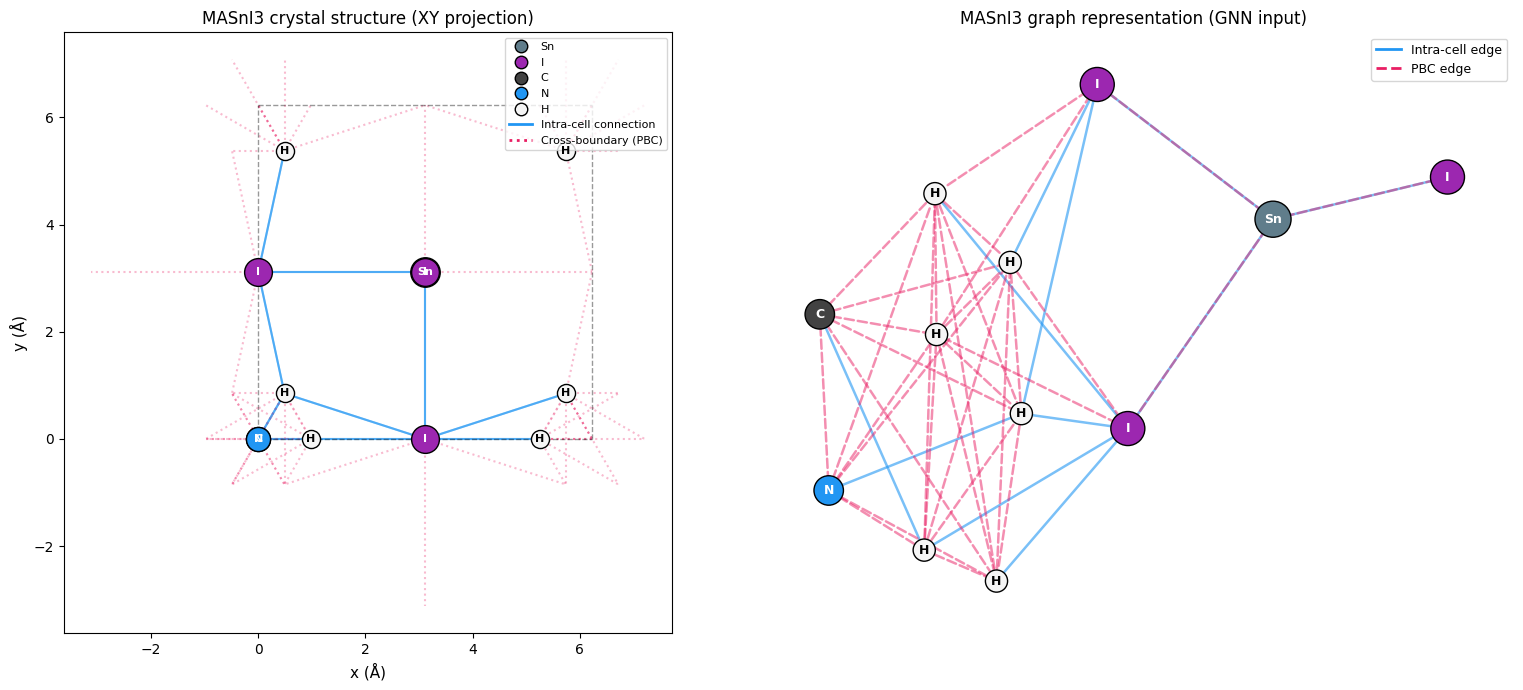

Crystal graph for MASnI3
Nodes: 12
Undirected periodic edges: 44
Cutoff radius: 3.5 Å
Neighbor distances: [np.float64(1.04), np.float64(1.47), np.float64(1.7), np.float64(2.06), np.float64(2.38), np.float64(2.92), np.float64(2.95), np.float64(3.08), np.float64(3.12), np.float64(3.43)] Å

Blue edges = intra-cell connections
Pink dashed edges = periodic boundary connections


In [ ]:
# Crystal graph visualization of MASnI3
# Left: XY projection
# Right: Graph representation for GNN

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import numpy as np
import networkx as nx

# ========================================
# 1. Build neighbor list
# ========================================

cutoff = 3.5  # Å
all_neighbors = masni3.get_all_neighbors(cutoff)

colors_map = {
    'Sn': '#607D8B',
    'I':  '#9C27B0',
    'C':  '#424242',
    'N':  '#2196F3',
    'H':  '#F5F5F5'
}

sizes_map = {
    'Sn': 450,
    'I': 400,
    'C': 300,
    'N': 300,
    'H': 170
}

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# ========================================
# LEFT PANEL: XY projection
# ========================================

ax = axes[0]
bond_dists = set()

for i_atom, nbrs in enumerate(all_neighbors):

    p1 = masni3.cart_coords[i_atom]

    for nbr in nbrs:

        bond_dists.add(round(nbr.nn_distance, 2))

        # Identify PBC using periodic image offset
        image = tuple(int(v) for v in nbr.image)
        is_pbc = any(v != 0 for v in image)

        color = '#E91E63' if is_pbc else '#2196F3'
        style = ':' if is_pbc else '-'
        alpha = 0.30 if is_pbc else 0.55

        p2 = nbr.coords

        ax.plot(
            [p1[0], p2[0]],
            [p1[1], p2[1]],
            color=color,
            linestyle=style,
            linewidth=1.5,
            alpha=alpha,
            zorder=1
        )

# Draw atoms
for i_atom, site in enumerate(masni3):

    element = site.species_string
    col = colors_map[element]

    ax.scatter(
        site.coords[0],
        site.coords[1],
        s=sizes_map[element],
        c=col,
        edgecolors='black',
        linewidths=1.0,
        zorder=5
    )

    label_color = 'black' if element == 'H' else 'white'

    ax.text(
        site.coords[0],
        site.coords[1],
        element,
        ha='center',
        va='center',
        fontsize=8,
        fontweight='bold',
        color=label_color,
        zorder=6
    )

# Draw unit cell boundary
L = masni3.lattice.matrix

corners_2d = np.array([
    [0, 0],
    [L[0, 0], L[0, 1]],
    [L[1, 0], L[1, 1]],
    [L[0, 0] + L[1, 0], L[0, 1] + L[1, 1]]
])

for a_idx, b_idx in [(0, 1), (0, 2), (1, 3), (2, 3)]:

    ax.plot(
        [corners_2d[a_idx, 0], corners_2d[b_idx, 0]],
        [corners_2d[a_idx, 1], corners_2d[b_idx, 1]],
        'k--',
        linewidth=1.0,
        alpha=0.4
    )

ax.set_xlabel('x (Å)', fontsize=11)
ax.set_ylabel('y (Å)', fontsize=11)
ax.set_title('MASnI3 crystal structure (XY projection)', fontsize=12)
ax.set_aspect('equal')

# Legend
atom_handles = [
    Line2D(
        [0], [0],
        marker='o',
        color='w',
        markerfacecolor=color,
        markeredgecolor='black',
        markersize=9,
        label=element
    )
    for element, color in colors_map.items()
]

intra_h = Line2D(
    [0], [0], color='#2196F3',
    lw=2, label='Intra-cell connection'
)

cross_h = Line2D(
    [0], [0], color='#E91E63',
    lw=2, ls=':', label='Cross-boundary (PBC)'
)

ax.legend(
    handles=atom_handles + [intra_h, cross_h],
    fontsize=8,
    loc='upper right'
)

# ========================================
# RIGHT PANEL: Crystal graph
# ========================================

ax2 = axes[1]

# MultiGraph preserves multiple periodic edges
G = nx.MultiGraph()

for i_atom in range(masni3.num_sites):
    G.add_node(
        i_atom,
        element=masni3[i_atom].species_string
    )

# Add unique neighbor connections
seen_edges = set()

for i_atom, nbrs in enumerate(all_neighbors):

    for nbr in nbrs:

        j_atom = nbr.index
        image = tuple(int(v) for v in nbr.image)

        # Canonical representation of an undirected
        # periodic edge, including image displacement
        edge_a = (i_atom, j_atom, image)
        edge_b = (
            j_atom,
            i_atom,
            tuple(-v for v in image)
        )

        key = min(edge_a, edge_b)

        if key in seen_edges:
            continue

        seen_edges.add(key)

        is_pbc = any(v != 0 for v in image)

        G.add_edge(
            i_atom,
            j_atom,
            dist=float(nbr.nn_distance),
            pbc=is_pbc,
            image=image
        )

# Graph layout
pos = nx.kamada_kawai_layout(G)

node_colors = [
    colors_map[masni3[n].species_string]
    for n in G.nodes
]

node_sizes = [
    sizes_map[masni3[n].species_string] * 1.5
    for n in G.nodes
]

# Separate normal and PBC connections
normal_edges = [
    (u, v, k)
    for u, v, k, d in G.edges(keys=True, data=True)
    if not d['pbc']
]

pbc_edges = [
    (u, v, k)
    for u, v, k, d in G.edges(keys=True, data=True)
    if d['pbc']
]

nx.draw_networkx_edges(
    G,
    pos,
    edgelist=normal_edges,
    ax=ax2,
    edge_color='#2196F3',
    width=1.8,
    alpha=0.6
)

nx.draw_networkx_edges(
    G,
    pos,
    edgelist=pbc_edges,
    ax=ax2,
    edge_color='#E91E63',
    width=1.8,
    style='dashed',
    alpha=0.5
)

nx.draw_networkx_nodes(
    G,
    pos,
    ax=ax2,
    node_color=node_colors,
    node_size=node_sizes,
    edgecolors='black',
    linewidths=1.0
)

labels = {
    n: masni3[n].species_string
    for n in G.nodes
}

# Draw labels individually for correct text contrast
for n, (x, y) in pos.items():

    element = masni3[n].species_string

    ax2.text(
        x, y,
        element,
        ha='center',
        va='center',
        fontsize=9,
        fontweight='bold',
        color='black' if element == 'H' else 'white',
        zorder=10
    )

ax2.set_title(
    'MASnI3 graph representation (GNN input)',
    fontsize=12
)

intra_line = Line2D(
    [0], [0],
    color='#2196F3',
    lw=2,
    label='Intra-cell edge'
)

pbc_line = Line2D(
    [0], [0],
    color='#E91E63',
    lw=2,
    ls='--',
    label='PBC edge'
)

ax2.legend(
    handles=[intra_line, pbc_line],
    fontsize=9,
    loc='upper right'
)

ax2.axis('off')

plt.tight_layout()
plt.show()

# ========================================
# Graph information
# ========================================

print("Crystal graph for MASnI3")
print(f"Nodes: {G.number_of_nodes()}")
print(f"Undirected periodic edges: {G.number_of_edges()}")
print(f"Cutoff radius: {cutoff} Å")
print(f"Neighbor distances: {sorted(bond_dists)} Å")

print()
print("Blue edges = intra-cell connections")
print("Pink dashed edges = periodic boundary connections")

# **1.5.3**

In [ ]:
import numpy as np

# Translate all MASnI3 atoms by a fractional vector
shift = np.array([0.3, 0.15, 0.42])

masni3_shifted = masni3.copy()

for i in range(len(masni3_shifted)):
    new_frac = (masni3_shifted[i].frac_coords + shift) % 1.0
    masni3_shifted.replace(
        i,
        masni3_shifted[i].species,
        new_frac
    )

# Rebuild neighbor lists
cutoff = 3.5  # Å

nbrs_orig = masni3.get_all_neighbors(cutoff)
nbrs_shift = masni3_shifted.get_all_neighbors(cutoff)

# Compare sorted distance lists
dists_orig = sorted([
    n.nn_distance
    for nbrs in nbrs_orig
    for n in nbrs
])

dists_shift = sorted([
    n.nn_distance
    for nbrs in nbrs_shift
    for n in nbrs
])

print(f"Shift vector (fractional): {shift}")
print(f"Original distances:  {[f'{d:.4f}' for d in dists_orig[:8]]} ...")
print(f"Shifted distances:   {[f'{d:.4f}' for d in dists_shift[:8]]} ...")

assert len(dists_orig) == len(dists_shift), "Neighbor counts differ!"

max_diff = max(
    (abs(a - b) for a, b in zip(dists_orig, dists_shift)),
    default=0.0
)

print(f"Max difference:      {max_diff:.2e}")
print()

if max_diff < 1e-6:
    print("Translation invariance verified!")
    print("The periodic crystal graph preserves its neighbor distances.")
else:
    print("Check numerical tolerance and cutoff boundary effects.")

# PyVista side-by-side visualization
try:
    from crystal_viz import plot_crystal_grid
    from IPython.display import display

    img = plot_crystal_grid(
        [masni3, masni3_shifted],
        titles=[
            "Original MASnI3",
            "Translated by (0.3, 0.15, 0.42)"
        ],
        ncols=2,
        atom_scale=0.3,
        elevation=65
    )

    print("Different fractional coordinates, same periodic MASnI3 crystal.")

except ImportError:
    print("crystal_viz is not available; numerical verification completed.")

Shift vector (fractional): [0.3  0.15 0.42]
Original distances:  ['1.0400', '1.0400', '1.0400', '1.0400', '1.0400', '1.0400', '1.0400', '1.0400'] ...
Shifted distances:   ['1.0400', '1.0400', '1.0400', '1.0400', '1.0400', '1.0400', '1.0400', '1.0400'] ...
Max difference:      2.22e-15

Translation invariance verified!
The periodic crystal graph preserves its neighbor distances.
crystal_viz is not available; numerical verification completed.


# **1.6**

In [ ]:
import pandas as pd
import os
from pymatgen.core import Composition

# Load the SCIGEN training data (MP-20 dataset)
PROJECT_DIR = os.environ.get('PROJECT_ROOT', '/content/APS_demo_SCIGEN')

df = pd.read_csv(
    os.path.join(PROJECT_DIR, 'data', 'mp_20', 'train.csv')
)

print(f'Dataset: {len(df)} structures')
print(f'Columns: {list(df.columns)}')

# Target material: MASnI3 (CH3NH3SnI3)
target = Composition("CH6NSnI3").reduced_composition

# Search for MASnI3 in the training dataset
masni3_df = df[
    df['pretty_formula'].apply(
        lambda x: Composition(x).reduced_composition == target
        if pd.notna(x) else False
    )
]

print()
print("=" * 55)
print("MASnI3 (CH3NH3SnI3) — Dataset Search")
print("=" * 55)
print(f"Total MP-20 training structures: {len(df)}")
print(f"MASnI3 structures found: {len(masni3_df)}")

if len(masni3_df) > 0:
    print("\nMatching structures:")
    print(masni3_df[
        ['material_id', 'pretty_formula',
         'formation_energy_per_atom', 'band_gap']
    ].to_string(index=False))
else:
    print("\nMASnI3 was not found in the MP-20 training dataset.")

Dataset: 27136 structures
Columns: ['Unnamed: 0.1', 'Unnamed: 0', 'material_id', 'formation_energy_per_atom', 'band_gap', 'pretty_formula', 'e_above_hull', 'elements', 'cif', 'spacegroup.number', 'spacegroup.number.conv', 'cif.conv']


/usr/lib/python3.13/functools.py:1025: UserWarning: No Pauling electronegativity for He. Setting to NaN. This has no physical meaning, and is mainly done to avoid errors caused by the code expecting a float.
  val = self.func(instance)
/usr/lib/python3.13/functools.py:1025: UserWarning: No Pauling electronegativity for Ne. Setting to NaN. This has no physical meaning, and is mainly done to avoid errors caused by the code expecting a float.
  val = self.func(instance)



MASnI3 (CH3NH3SnI3) — Dataset Search
Total MP-20 training structures: 27136
MASnI3 structures found: 0

MASnI3 was not found in the MP-20 training dataset.


In [ ]:
from pymatgen.core import Composition
import pandas as pd

# Target material: MASnI3 (CH3NH3SnI3)
target = Composition("CH6NSnI3").reduced_composition

# Filter MASnI3 structures from MP-20
masni3_df = df[
    df['pretty_formula'].apply(
        lambda x: Composition(str(x)).reduced_composition == target
        if pd.notna(x) else False
    )
]

# Display MASnI3 information
print(f"MASnI3 structures found: {len(masni3_df)}")

display(masni3_df[
    ['material_id', 'pretty_formula',
     'formation_energy_per_atom',
     'e_above_hull', 'spacegroup.number']
].head(10))

MASnI3 structures found: 0


,material_id,pretty_formula,formation_energy_per_atom,e_above_hull,spacegroup.number


In [ ]:
from pymatgen.core import Structure

# Parse MASnI3 structure from the dataset
if len(masni3_df) > 0:

    row = masni3_df.iloc[0]
    struct = Structure.from_str(row['cif'], fmt='cif')

    print(f'Structure: {row["pretty_formula"]} ({row["material_id"]})')
    print(f'Atoms: {struct.num_sites}')
    print(f'DFT formation energy: {row["formation_energy_per_atom"]:.4f} eV/atom')

else:
    # Use manually constructed MASnI3 structure
    struct = masni3.copy()

    print('Structure: MASnI3 (CH3NH3SnI3)')
    print(f'Atoms: {struct.num_sites}')
    print('DFT formation energy: Not available')
    print('Source: Manually constructed initial structure')

# Export CIF
struct.to(fmt='cif', filename='MASnI3_structure.cif')
print('CIF file saved: MASnI3_structure.cif')

Structure: MASnI3 (CH3NH3SnI3)
Atoms: 12
DFT formation energy: Not available
Source: Manually constructed initial structure
CIF file saved: MASnI3_structure.cif


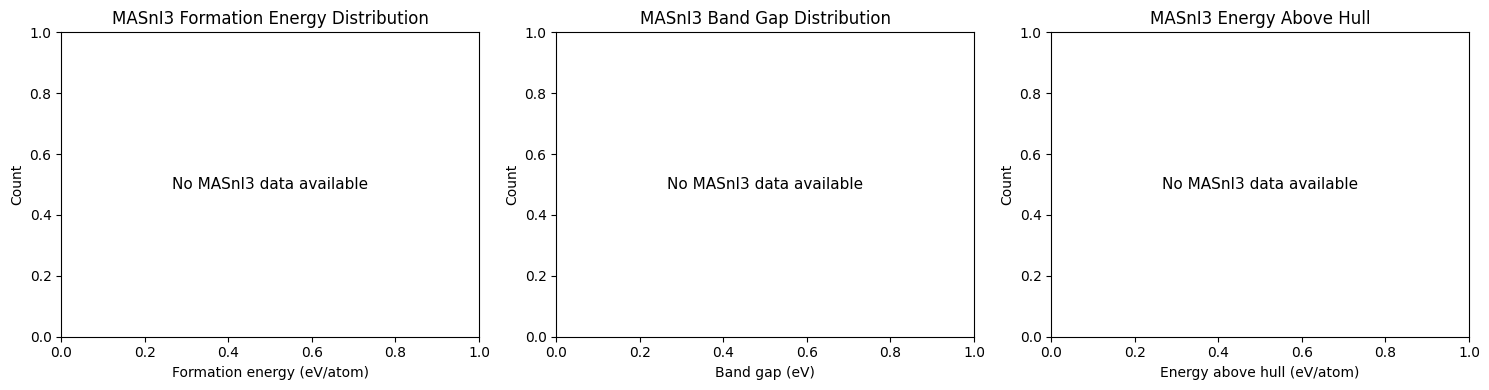

MASnI3 structures found: 0


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# MASnI3 dataset
data = masni3_df.copy()

columns = [
    'formation_energy_per_atom',
    'band_gap',
    'e_above_hull'
]

titles = [
    'MASnI3 Formation Energy Distribution',
    'MASnI3 Band Gap Distribution',
    'MASnI3 Energy Above Hull'
]

xlabels = [
    'Formation energy (eV/atom)',
    'Band gap (eV)',
    'Energy above hull (eV/atom)'
]

colors = ['steelblue', 'coral', 'seagreen']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, column, title, xlabel, color in zip(
    axes, columns, titles, xlabels, colors
):
    # Convert to numerical values
    values = pd.to_numeric(data[column], errors='coerce').dropna()

    if len(values) > 1:
        ax.hist(
            values,
            bins=min(20, len(values)),
            color=color,
            edgecolor='white'
        )

    elif len(values) == 1:
        # Only one structure: show a single data point
        ax.scatter(
            values.iloc[0], 1,
            color=color,
            s=120,
            zorder=5
        )
        ax.set_ylim(0, 1.5)
        ax.set_yticks([0, 1])

    else:
        ax.text(
            0.5, 0.5,
            'No MASnI3 data available',
            ha='center',
            va='center',
            transform=ax.transAxes,
            fontsize=11
        )

    ax.set_xlabel(xlabel)
    ax.set_ylabel('Count')
    ax.set_title(title)

plt.tight_layout()
plt.show()

print(f"MASnI3 structures found: {len(masni3_df)}")

# **下載CIF檔案**

In [ ]:
# Export MASnI3 CIF file
masni3.to(
    fmt="cif",
    filename="MASnI3_initial.cif"
)

print("MASnI3 CIF generated successfully!")

MASnI3 CIF generated successfully!


In [ ]:
import os

print(os.path.abspath("MASnI3_initial.cif"))

/content/MASnI3_initial.cif


In [ ]:
from google.colab import files

files.download("MASnI3_initial.cif")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Original MASnI3 unit cell
masni3_1x1x1 = masni3.copy()

# 2x2x2 MASnI3 supercell
masni3_2x2x2 = masni3.copy()
masni3_2x2x2.make_supercell([2, 2, 2])

# Export both structures
masni3_1x1x1.to(
    fmt="cif",
    filename="MASnI3_1x1x1.cif"
)

masni3_2x2x2.to(
    fmt="cif",
    filename="MASnI3_2x2x2.cif"
)

print("1x1x1:", masni3_1x1x1.num_sites, "atoms")
print("2x2x2:", masni3_2x2x2.num_sites, "atoms")
print("Both CIF files generated successfully!")

1x1x1: 12 atoms
2x2x2: 96 atoms
Both CIF files generated successfully!
